In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


##Classifier Classes

In [8]:
import numpy as np
import matplotlib.pyplot as plt

class BaseClassifier:
    def split_data(self, X, y, seed=42):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)

        rng = np.random.default_rng(seed)
        train_idx = []
        dev_idx = []
        test_idx = []

        for label in np.unique(y):
            idx = np.where(y == label)[0]
            rng.shuffle(idx)

            n = len(idx)
            n_train = int(0.60 * n)
            n_dev = int(0.20 * n)

            train_idx.extend(idx[:n_train])
            dev_idx.extend(idx[n_train:n_train+n_dev])
            test_idx.extend(idx[n_train+n_dev:])

        train_idx = np.array(train_idx)
        dev_idx = np.array(dev_idx)
        test_idx = np.array(test_idx)

        rng.shuffle(train_idx)
        rng.shuffle(dev_idx)
        rng.shuffle(test_idx)

        return (
            X[train_idx], X[dev_idx], X[test_idx],
            y[train_idx], y[dev_idx], y[test_idx]
        )

    def validate(self, X_dev, y_dev):
        predictions = self.predict(X_dev)
        accuracy = np.mean(predictions == y_dev)

        print("Validation Accuracy:", accuracy)
        self.confusion_matrix(y_dev, predictions)

        return accuracy

    def confusion_matrix(self, y_true, y_pred):
        labels = np.unique(np.concatenate([y_true, y_pred]))

        matrix = np.zeros(
            (len(labels), len(labels)), dtype=int
        )

        for actual, predicted in zip(y_true, y_pred):
            i = np.where(labels == actual)[0][0]
            j = np.where(labels == predicted)[0][0]
            matrix[i, j] += 1

        print("Confusion Matrix:\n", matrix)

        plt.figure(figsize=(6, 5))
        plt.imshow(matrix, cmap="Blues")
        plt.colorbar()

        plt.xticks(range(len(labels)), labels)
        plt.yticks(range(len(labels)), labels)

        plt.xlabel("Predicted Label")
        plt.ylabel("Actual Label")
        plt.title("Confusion Matrix")

        for i in range(len(labels)):
            for j in range(len(labels)):
                plt.text(j, i, matrix[i, j],
                         ha="center", va="center")

        plt.show()

        accuracy = np.trace(matrix) / np.sum(matrix)
        print("Accuracy:", accuracy)

        return matrix

    def plot(self, X, y, title="Decision Boundary"):
        if X.shape[1] != 2:
            print("Plotting requires exactly 2 features.")
            return

        x_min, x_max = X[:, 0].min()-1, X[:, 0].max()+1
        y_min, y_max = X[:, 1].min()-1, X[:, 1].max()+1

        xx, yy = np.meshgrid(
            np.linspace(x_min, x_max, 200),
            np.linspace(y_min, y_max, 200)
        )

        grid = np.c_[xx.ravel(), yy.ravel()]
        Z = self.predict(grid)
        Z = Z.reshape(xx.shape)

        plt.figure(figsize=(8, 6))
        plt.contourf(xx, yy, Z, alpha=0.3, cmap="viridis")
        plt.scatter(X[:, 0], X[:, 1], c=y,
                    edgecolors="black", cmap="viridis")

        plt.xlabel("Feature 1")
        plt.ylabel("Feature 2")
        plt.title(title)
        plt.show()

In [9]:
class GMMClassifier(BaseClassifier):

    def __init__(self, K=2, max_iter=100, tol=1e-4):
        self.K = K
        self.max_iter = max_iter
        self.tol = tol

    def log_gaussian(self, X, mean, cov):
        d = X.shape[1]
        cov = cov + 1e-6 * np.eye(d)

        diff = X - mean
        sign, logdet = np.linalg.slogdet(cov)

        if sign <= 0:
            return np.full(len(X), -np.inf)

        inv = np.linalg.inv(cov)
        exponent = np.sum((diff @ inv) * diff, axis=1)

        return -0.5 * (
            d * np.log(2 * np.pi) + logdet + exponent
        )

    def logsumexp(self, A):
        m = np.max(A, axis=1, keepdims=True)
        return (m + np.log(np.sum(
            np.exp(A - m), axis=1, keepdims=True
        ))).ravel()

    def fit_gmm(self, X):
        n, d = X.shape
        rng = np.random.default_rng(42)

        means = X[rng.choice(n, self.K, replace=False)]
        covs = np.array([np.cov(X.T) + 1e-6*np.eye(d)
                         for _ in range(self.K)])
        weights = np.ones(self.K) / self.K

        previous_ll = -np.inf

        for _ in range(self.max_iter):

            log_prob = np.zeros((n, self.K))

            for k in range(self.K):
                log_prob[:, k] = (
                    np.log(weights[k] + 1e-12) +
                    self.log_gaussian(X, means[k], covs[k])
                )

            log_total = self.logsumexp(log_prob)
            responsibilities = np.exp(
                log_prob - log_total[:, None]
            )

            Nk = responsibilities.sum(axis=0) + 1e-10

            weights = Nk / n
            means = (responsibilities.T @ X) / Nk[:, None]

            for k in range(self.K):
                diff = X - means[k]
                covs[k] = (
                    (diff.T * responsibilities[:, k]) @ diff
                    / Nk[k]
                )
                covs[k] += 1e-6 * np.eye(d)

            current_ll = np.sum(log_total)

            if abs(current_ll - previous_ll) < self.tol:
                break

            previous_ll = current_ll

        return weights, means, covs

    def fit(self, X_train, y_train):
        self.classes = np.unique(y_train)
        self.models = {}

        for label in self.classes:
            X_class = X_train[y_train == label]
            self.models[label] = self.fit_gmm(X_class)

    def predict(self, X):
        scores = []

        for label in self.classes:
            weights, means, covs = self.models[label]

            component_scores = []

            for k in range(self.K):
                component_scores.append(
                    np.log(weights[k] + 1e-12) +
                    self.log_gaussian(X, means[k], covs[k])
                )

            scores.append(
                self.logsumexp(np.column_stack(component_scores))
            )

        scores = np.column_stack(scores)
        return self.classes[np.argmax(scores, axis=1)]

In [10]:
class LDAClassifier(BaseClassifier):

    def fit(self, X_train, y_train):
        self.classes = np.unique(y_train)
        n, d = X_train.shape

        self.means = []
        self.priors = []

        covariance = np.zeros((d, d))

        for label in self.classes:
            X_class = X_train[y_train == label]

            mean = np.mean(X_class, axis=0)
            self.means.append(mean)

            self.priors.append(len(X_class) / n)

            diff = X_class - mean
            covariance += diff.T @ diff

        self.means = np.array(self.means)
        self.priors = np.array(self.priors)

        covariance /= (n - len(self.classes))
        covariance += 1e-6 * np.eye(d)

        self.inv_cov = np.linalg.pinv(covariance)

    def predict(self, X):
        scores = []

        for i in range(len(self.classes)):
            mean = self.means[i]

            score = (
                X @ self.inv_cov @ mean
                - 0.5 * mean @ self.inv_cov @ mean
                + np.log(self.priors[i])
            )

            scores.append(score)

        scores = np.column_stack(scores)

        return self.classes[np.argmax(scores, axis=1)]

In [11]:

class KNNClassifier(BaseClassifier):

    def __init__(self, K=5):
        self.K = K

    def fit(self, X_train, y_train):
        self.X_train = np.asarray(X_train, dtype=float)
        self.y_train = np.asarray(y_train)

    def predict(self, X):
        predictions = []

        for sample in X:
            distances = np.sqrt(
                np.sum((self.X_train - sample)**2, axis=1)
            )

            nearest = np.argsort(distances)[:self.K]

            labels = self.y_train[nearest]
            unique, counts = np.unique(
                labels, return_counts=True
            )

            predictions.append(unique[np.argmax(counts)])

        return np.array(predictions)

In [12]:
class SVMClassifier(BaseClassifier):

    def __init__(self, lr=0.001, epochs=1000, C=1.0):
        self.lr = lr
        self.epochs = epochs
        self.C = C

    def fit(self, X_train, y_train):
        self.classes = np.unique(y_train)

        self.mean = X_train.mean(axis=0)
        self.std = X_train.std(axis=0) + 1e-8

        X = (X_train - self.mean) / self.std

        n, d = X.shape

        self.weights = np.zeros((len(self.classes), d))
        self.bias = np.zeros(len(self.classes))

        for i, label in enumerate(self.classes):

            y = np.where(y_train == label, 1, -1)

            w = np.zeros(d)
            b = 0.0

            for _ in range(self.epochs):

                scores = X @ w + b
                margins = y * scores

                active = margins < 1

                dw = w - self.C * np.sum(
                    (y[active, None] * X[active]), axis=0
                ) / n

                db = -self.C * np.sum(y[active]) / n

                w -= self.lr * dw
                b -= self.lr * db

            self.weights[i] = w
            self.bias[i] = b

    def predict(self, X):
        X = (X - self.mean) / self.std

        scores = X @ self.weights.T + self.bias

        return self.classes[np.argmax(scores, axis=1)]


##Synthetic

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
path = "/content/drive/MyDrive/Krithik SNU/HAM/Synthetic Data/data.pkl"
import pickle
with open(path, "rb") as f:
    data = pickle.load(f)

X = data["x"]
y = data["y"]

# Shuffle dataset
np.random.seed(42)
indices = np.random.permutation(len(X))

X = np.array(X)[indices]
y = np.array(y)[indices]

# 70:15:15 split
n = len(X)
train_end = int(0.70 * n)
dev_end = int(0.85 * n)

X_train = X[:train_end]
y_train = y[:train_end]

X_dev = X[train_end:dev_end]
y_dev = y[train_end:dev_end]

X_test = X[dev_end:]
y_test = y[dev_end:]

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_dev.shape, y_dev.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (14000, 16) (14000,)
Development: (3000, 16) (3000,)
Testing: (3000, 16) (3000,)
Training: (14000, 16) (14000,)
Validation: (3000, 16) (3000,)
Testing: (3000, 16) (3000,)



Validation Results
Validation Accuracy: 1.0
Confusion Matrix:
 [[1502    0]
 [   0 1498]]


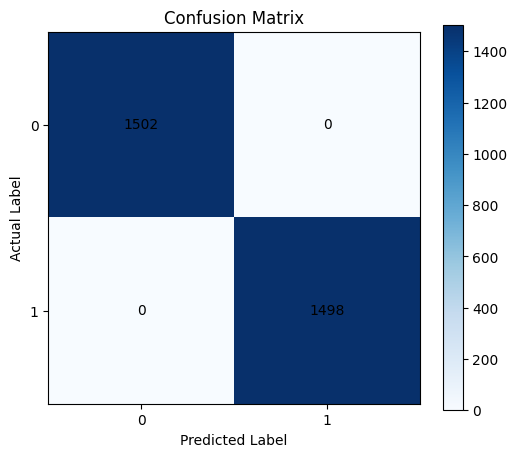

Accuracy: 1.0

Testing Results
Confusion Matrix:
 [[1543    0]
 [   0 1457]]


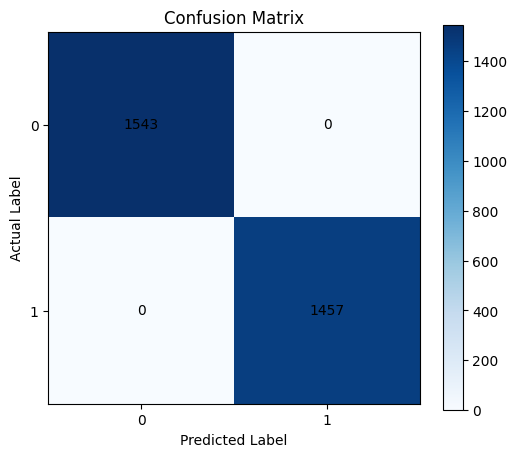

Accuracy: 1.0
Plotting requires exactly 2 features.


In [ ]:
model = GMMClassifier()
model.fit(X_train, y_train)
print("\nValidation Results")
model.validate(X_dev, y_dev)

print("\nTesting Results")
y_pred = model.predict(X_test)

model.confusion_matrix(y_test, y_pred)
model.plot(X_test, y_test, "LDA Decision Boundary")



Validation Results
Validation Accuracy: 0.964
Confusion Matrix:
 [[1448   54]
 [  54 1444]]


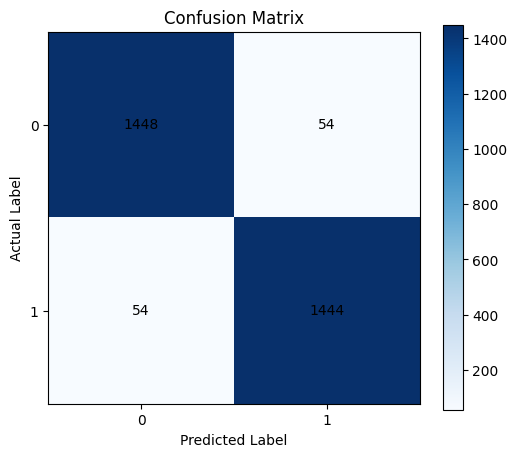

Accuracy: 0.964

Testing Results
Confusion Matrix:
 [[1487   56]
 [  45 1412]]


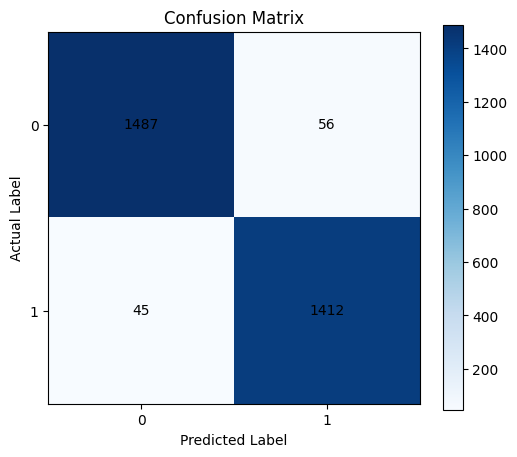

Accuracy: 0.9663333333333334
Plotting requires exactly 2 features.


In [ ]:
model = LDAClassifier()
model.fit(X_train, y_train)
print("\nValidation Results")
model.validate(X_dev, y_dev)

print("\nTesting Results")
y_pred = model.predict(X_test)

model.confusion_matrix(y_test, y_pred)
model.plot(X_test, y_test, "LDA Decision Boundary")



Validation Results
Validation Accuracy: 0.9953333333333333
Confusion Matrix:
 [[1492   10]
 [   4 1494]]


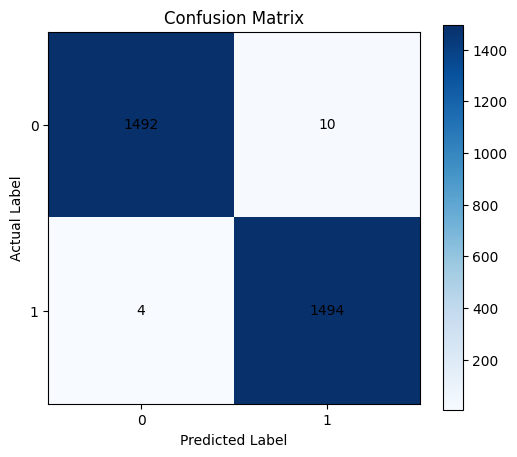

Accuracy: 0.9953333333333333

Testing Results
Confusion Matrix:
 [[1535    8]
 [   8 1449]]


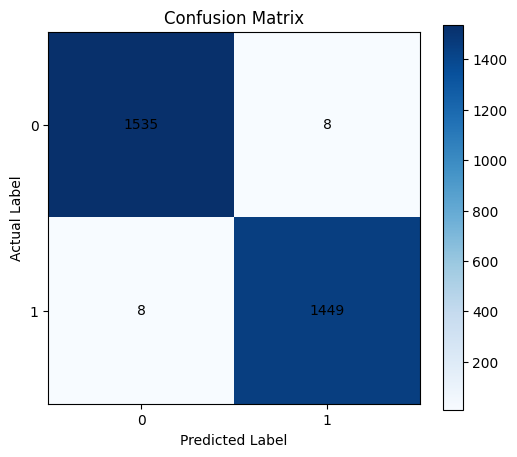

Accuracy: 0.9946666666666667
Plotting requires exactly 2 features.


In [ ]:
model = KNNClassifier()
model.fit(X_train, y_train)
print("\nValidation Results")
model.validate(X_dev, y_dev)

print("\nTesting Results")
y_pred = model.predict(X_test)

model.confusion_matrix(y_test, y_pred)
model.plot(X_test, y_test, "KNN Decision Boundary")


Validation Results
Validation Accuracy: 0.954
Confusion Matrix:
 [[1399  103]
 [  35 1463]]


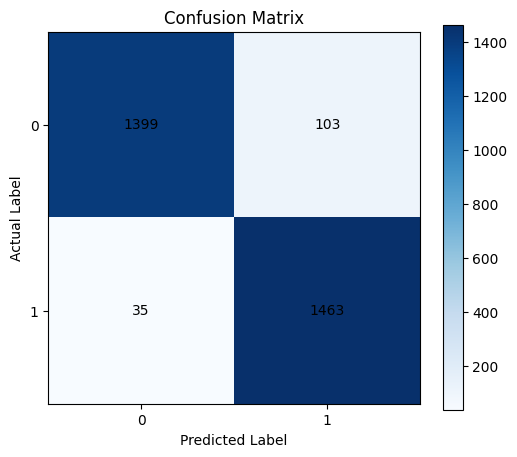

Accuracy: 0.954

Testing Results
Confusion Matrix:
 [[1448   95]
 [  41 1416]]


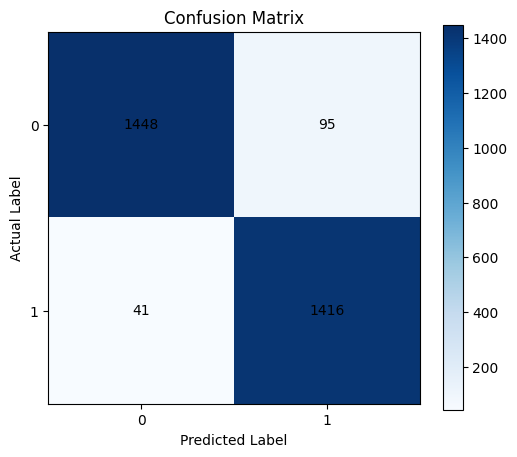

Accuracy: 0.9546666666666667
Plotting requires exactly 2 features.


In [ ]:
model = SVMClassifier()
model.fit(X_train, y_train)
print("\nValidation Results")
model.validate(X_dev, y_dev)

print("\nTesting Results")
y_pred = model.predict(X_test)

model.confusion_matrix(y_test, y_pred)
model.plot(X_test, y_test, "LDA Decision Boundary")

##MNIST

In [ ]:
import os
import numpy as np
from PIL import Image

from google.colab import drive
drive.mount('/content/drive')

base_path = "/content/drive/MyDrive/Krithik SNU/HAM/MNIST/Team 7"

digits = [3, 6, 8]

def load_split(split):

    X = []
    y = []

    for digit in digits:

        folder = os.path.join(base_path, split, str(digit))

        for filename in os.listdir(folder):

            filepath = os.path.join(folder, filename)

            if filename.lower().endswith(('.png', '.jpg', '.jpeg')):
                img = Image.open(filepath).convert('L')
                img = img.resize((28, 28))

                img = np.asarray(img, dtype=float) / 255.0

                X.append(img.flatten())
                y.append(digit)

    return np.array(X), np.array(y)

X_train, y_train = load_split("train")
X_dev, y_dev = load_split("dev")
X_test, y_test = load_split("test")

print("Training:", X_train.shape, y_train.shape)
print("Development:", X_dev.shape, y_dev.shape)
print("Testing:", X_test.shape, y_test.shape)

Mounted at /content/drive
Training: (14312, 784) (14312,)
Development: (3588, 784) (3588,)
Testing: (2942, 784) (2942,)


Validation Results
Validation Accuracy: 0.8985507246376812
Confusion Matrix:
 [[ 987   10  248]
 [   5 1118   43]
 [  47   11 1119]]


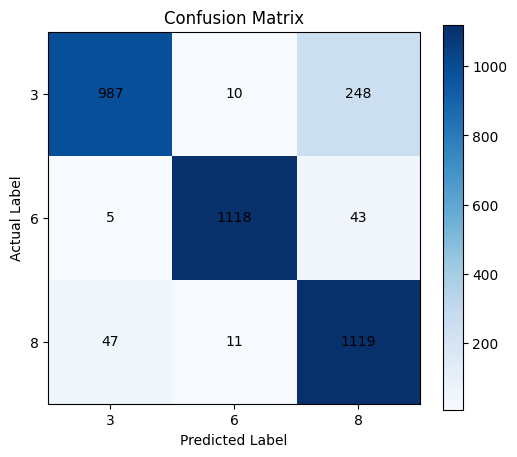

Accuracy: 0.8985507246376812
Testing Results
Confusion Matrix:
 [[834  10 166]
 [  6 915  37]
 [ 40   9 925]]


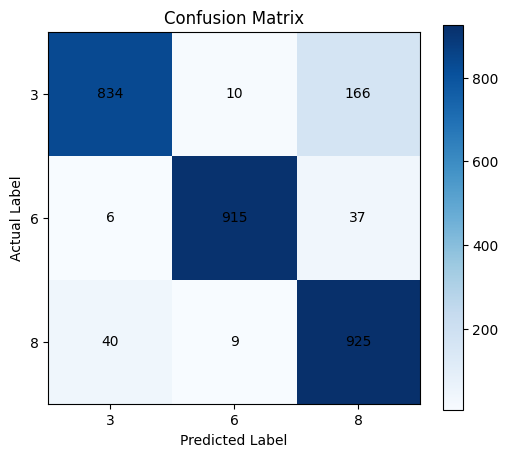

Accuracy: 0.9089055064581917


array([[834,  10, 166],
       [  6, 915,  37],
       [ 40,   9, 925]])

In [ ]:
model = GMMClassifier()

model.fit(X_train, y_train)

print("Validation Results")
model.validate(X_dev, y_dev)

print("Testing Results")
y_pred = model.predict(X_test)

model.confusion_matrix(y_test, y_pred)

Validation Results
Validation Accuracy: 0.9587513935340022
Confusion Matrix:
 [[1182   16   47]
 [   5 1130   31]
 [  38   11 1128]]


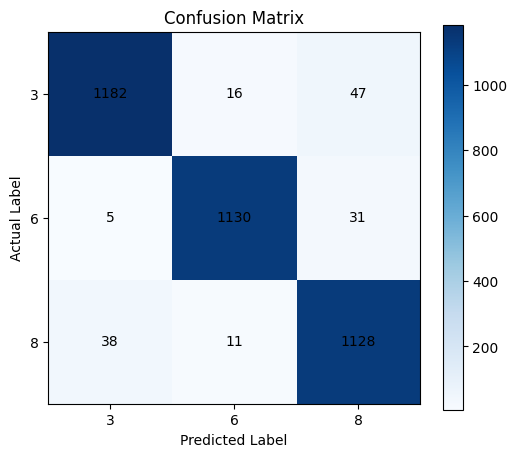

Accuracy: 0.9587513935340022
Testing Results
Confusion Matrix:
 [[954  11  45]
 [  2 928  28]
 [ 30  17 927]]


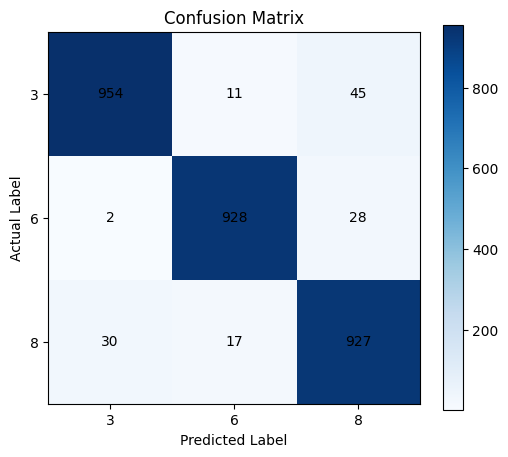

Accuracy: 0.9547926580557444


array([[954,  11,  45],
       [  2, 928,  28],
       [ 30,  17, 927]])

In [ ]:
model = LDAClassifier()

model.fit(X_train, y_train)

print("Validation Results")
model.validate(X_dev, y_dev)

print("Testing Results")
y_pred = model.predict(X_test)

model.confusion_matrix(y_test, y_pred)

Validation Results
Validation Accuracy: 0.987736900780379
Confusion Matrix:
 [[1233    3    9]
 [   1 1165    0]
 [  25    6 1146]]


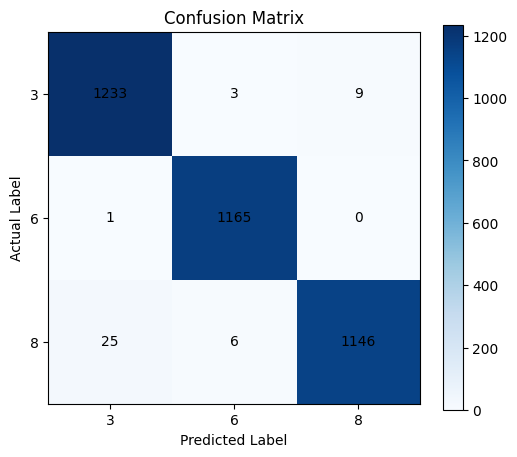

Accuracy: 0.987736900780379
Testing Results
Confusion Matrix:
 [[1003    1    6]
 [   0  958    0]
 [  21    3  950]]


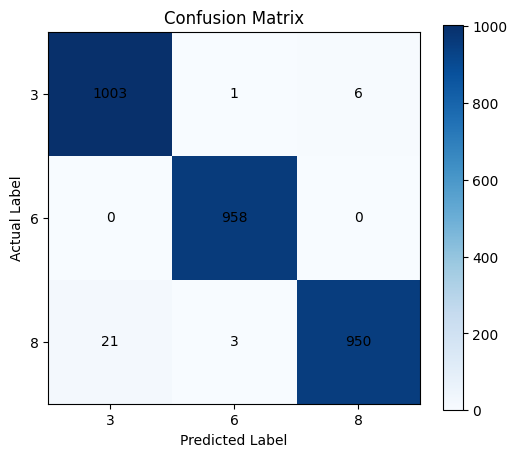

Accuracy: 0.9894629503738953


array([[1003,    1,    6],
       [   0,  958,    0],
       [  21,    3,  950]])

In [ ]:
model = KNNClassifier()

model.fit(X_train, y_train)

print("Validation Results")
model.validate(X_dev, y_dev)

print("Testing Results")
y_pred = model.predict(X_test)

model.confusion_matrix(y_test, y_pred)

Validation Results
Validation Accuracy: 0.955685618729097
Confusion Matrix:
 [[1174   18   53]
 [   4 1141   21]
 [  52   11 1114]]


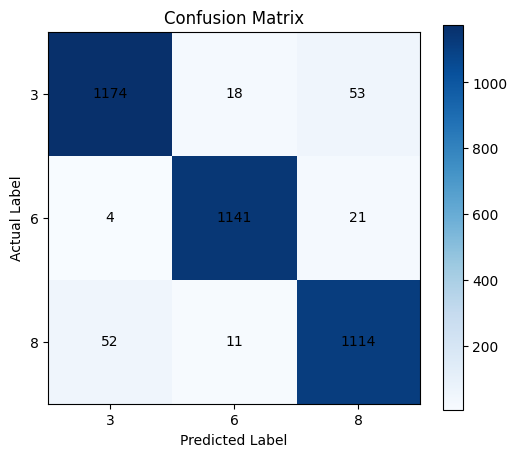

Accuracy: 0.955685618729097
Testing Results
Confusion Matrix:
 [[958  10  42]
 [  3 941  14]
 [ 32  12 930]]


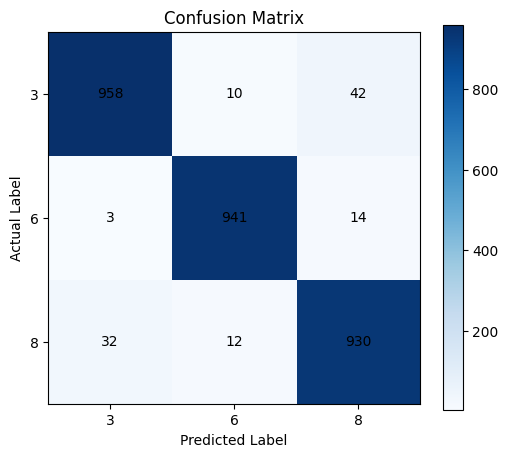

Accuracy: 0.9615907545887151


array([[958,  10,  42],
       [  3, 941,  14],
       [ 32,  12, 930]])

In [ ]:
model = SVMClassifier()

model.fit(X_train, y_train)

print("Validation Results")
model.validate(X_dev, y_dev)

print("Testing Results")
y_pred = model.predict(X_test)

model.confusion_matrix(y_test, y_pred)

##TIDIGTS


In [ ]:
sequences = []
labels = []
for digit in [8, 7, 2]:
    with np.load(f"/content/drive/MyDrive/Krithik SNU/HAM/TIDigits/{digit}.npz") as data:
        for key in data.files:
            sequences.append(data[key])
            labels.append(digit)

X = []
for sequence in sequences:
    parts = np.array_split(sequence, 4)
    means = [part.mean(axis=0) for part in parts]
    X.append(np.concatenate(means))
X = np.array(X)
y = np.array(labels)


Validation Results
Validation Accuracy: 0.9259259259259259
Confusion Matrix:
 [[90  0  0]
 [ 8 82  0]
 [12  0 78]]


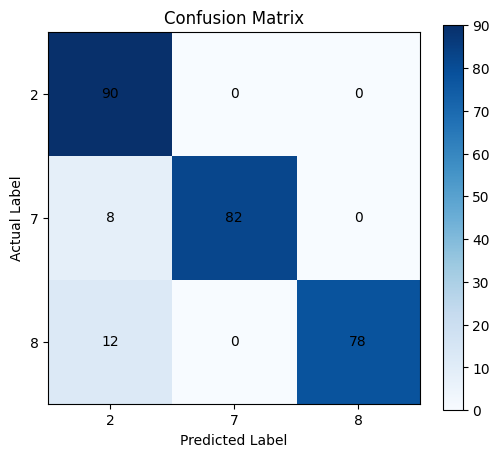

Accuracy: 0.9259259259259259

Testing Results
Confusion Matrix:
 [[88  2  0]
 [10 80  0]
 [ 9  0 81]]


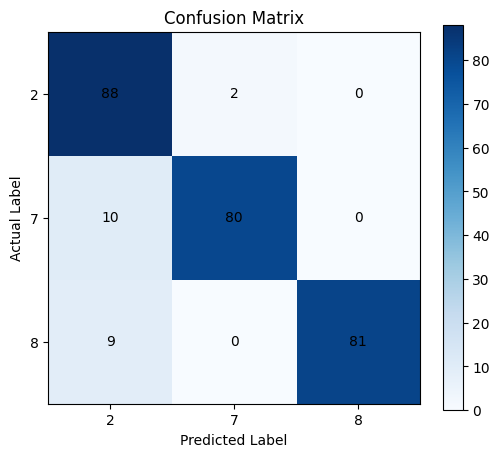

Accuracy: 0.9222222222222223


array([[88,  2,  0],
       [10, 80,  0],
       [ 9,  0, 81]])

In [ ]:
model = GMMClassifier()
X_train, X_dev, X_test, y_train, y_dev, y_test = model.split_data(X,y)
model.fit(X_train, y_train)
print("\nValidation Results")
model.validate(X_dev, y_dev)

print("\nTesting Results")
y_pred = model.predict(X_test)

model.confusion_matrix(y_test, y_pred)


Validation Results
Validation Accuracy: 0.9666666666666667
Confusion Matrix:
 [[86  2  2]
 [ 1 89  0]
 [ 4  0 86]]


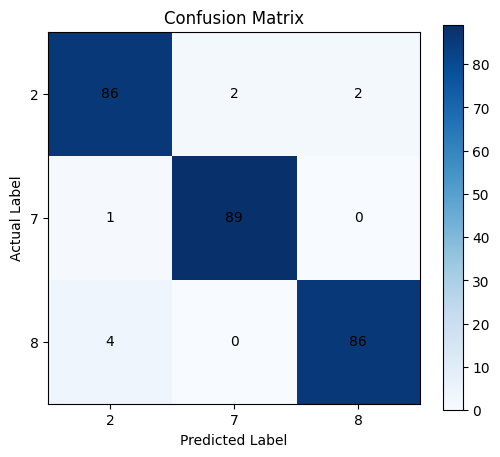

Accuracy: 0.9666666666666667

Testing Results
Confusion Matrix:
 [[88  0  2]
 [ 3 87  0]
 [ 3  0 87]]


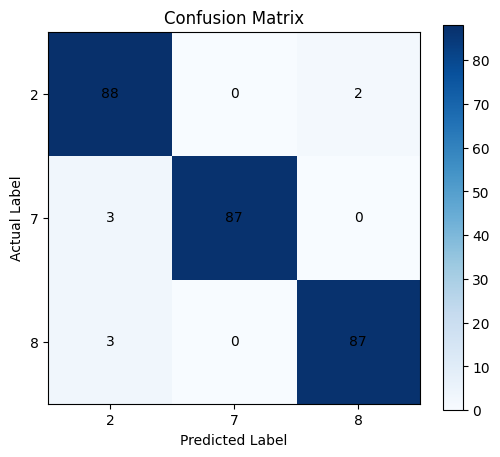

Accuracy: 0.9703703703703703


array([[88,  0,  2],
       [ 3, 87,  0],
       [ 3,  0, 87]])

In [ ]:
model = LDAClassifier()
X_train, X_dev, X_test, y_train, y_dev, y_test = model.split_data(X,y)
model.fit(X_train, y_train)
print("\nValidation Results")
model.validate(X_dev, y_dev)

print("\nTesting Results")
y_pred = model.predict(X_test)

model.confusion_matrix(y_test, y_pred)


Validation Results
Validation Accuracy: 0.9925925925925926
Confusion Matrix:
 [[90  0  0]
 [ 0 90  0]
 [ 2  0 88]]


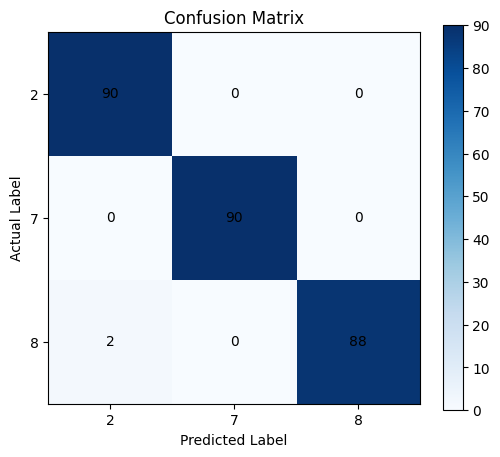

Accuracy: 0.9925925925925926

Testing Results
Confusion Matrix:
 [[88  1  1]
 [ 0 90  0]
 [ 2  0 88]]


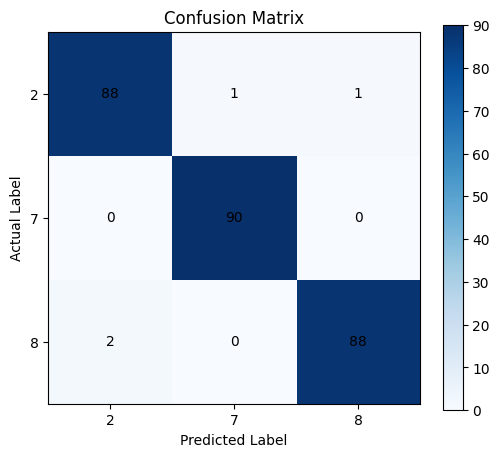

Accuracy: 0.9851851851851852


array([[88,  1,  1],
       [ 0, 90,  0],
       [ 2,  0, 88]])

In [ ]:
model = KNNClassifier()
X_train, X_dev, X_test, y_train, y_dev, y_test = model.split_data(X,y)
model.fit(X_train, y_train)
print("\nValidation Results")
model.validate(X_dev, y_dev)

print("\nTesting Results")
y_pred = model.predict(X_test)

model.confusion_matrix(y_test, y_pred)


Validation Results
Validation Accuracy: 0.9555555555555556
Confusion Matrix:
 [[84  1  5]
 [ 0 89  1]
 [ 4  1 85]]


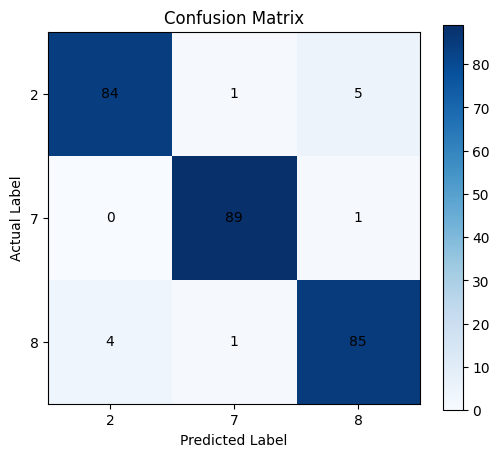

Accuracy: 0.9555555555555556

Testing Results
Confusion Matrix:
 [[83  1  6]
 [ 2 88  0]
 [ 5  0 85]]


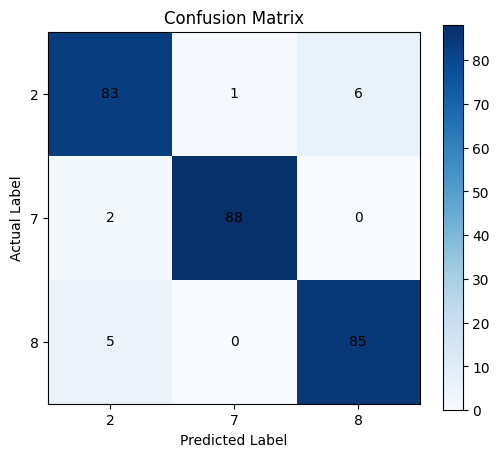

Accuracy: 0.9481481481481482


array([[83,  1,  6],
       [ 2, 88,  0],
       [ 5,  0, 85]])

In [ ]:
model = SVMClassifier()
X_train, X_dev, X_test, y_train, y_dev, y_test = model.split_data(X,y)
model.fit(X_train, y_train)
print("\nValidation Results")
model.validate(X_dev, y_dev)

print("\nTesting Results")
y_pred = model.predict(X_test)

model.confusion_matrix(y_test, y_pred)

##Image


In [ ]:
!echo "/content/drive/MyDrive/Krithik SNU/HAM/ImageFeatures/Dataset2"
!ls "/content/drive/MyDrive/Krithik SNU/HAM/ImageFeatures/Dataset2"

/content/drive/MyDrive/Krithik SNU/HAM/ImageFeatures/Dataset2
test_data.csv	train_data.csv	 val_data.csv
test_label.csv	train_label.csv  val_label.csv


In [ ]:

import numpy as np
import pandas as pd

from google.colab import drive
drive.mount('/content/drive')

base_path = "/content/drive/MyDrive/Krithik SNU/HAM/ImageFeatures/Dataset2/"

# Load training data
X_train = pd.read_csv(base_path + "train_data.csv").values.astype(float)
y_train = pd.read_csv(base_path + "train_label.csv").values.ravel()

# Load validation data
X_dev = pd.read_csv(base_path + "val_data.csv").values.astype(float)
y_dev = pd.read_csv(base_path + "val_label.csv").values.ravel()

# Load testing data
X_test = pd.read_csv(base_path + "test_data.csv").values.astype(float)
y_test = pd.read_csv(base_path + "test_label.csv").values.ravel()

# Display dataset information
print("Training:", X_train.shape, y_train.shape)
print("Development:", X_dev.shape, y_dev.shape)
print("Testing:", X_test.shape, y_test.shape)

print("Classes:", np.unique(y_train))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Training: (1999, 36) (1999,)
Development: (499, 36) (499,)
Testing: (499, 36) (499,)
Classes: [0. 1. 2. 3. 4.]



Validation Results
Validation Accuracy: 0.5551102204408818
Confusion Matrix:
 [[34 15 15  5 30]
 [21 49  7  7 16]
 [13  3 69 12  3]
 [ 8  3  7 76  6]
 [23 18  4  6 49]]


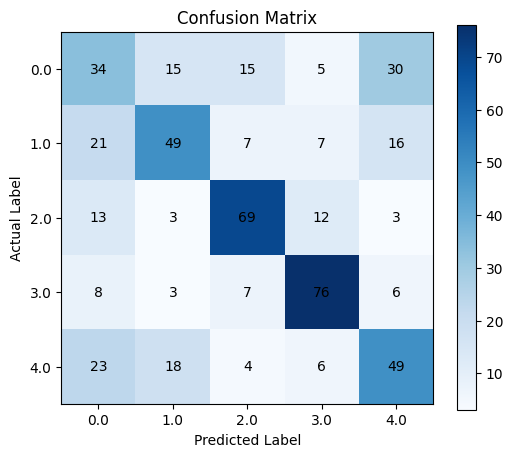

Accuracy: 0.5551102204408818

Testing Results
Confusion Matrix:
 [[34 22 17  9 17]
 [22 43 13  6 16]
 [ 4  9 76  6  5]
 [ 5  4 11 74  6]
 [30 12 11  5 42]]


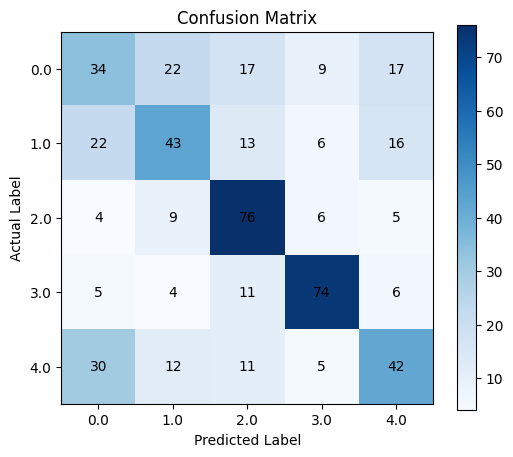

Accuracy: 0.5390781563126252
Plotting requires exactly 2 features.


In [ ]:
model = GMMClassifier()
model.fit(X_train, y_train)
print("\nValidation Results")
model.validate(X_dev, y_dev)

print("\nTesting Results")
y_pred = model.predict(X_test)

model.confusion_matrix(y_test, y_pred)
model.plot(X_test, y_test, "LDA Decision Boundary")


Validation Results
Validation Accuracy: 0.5651302605210421
Confusion Matrix:
 [[39 22  9  8 21]
 [29 53  3  5 10]
 [ 7 11 67 11  4]
 [ 8 10 11 64  7]
 [20 16  2  3 59]]


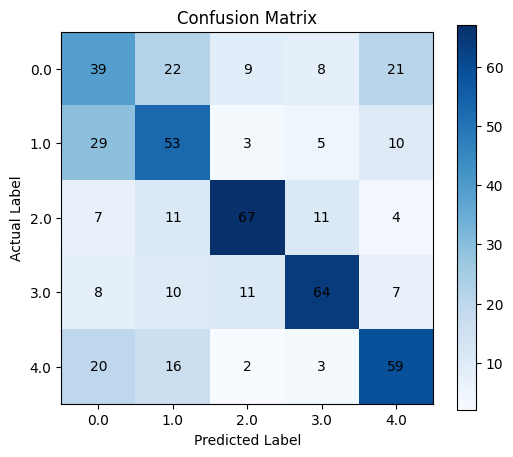

Accuracy: 0.5651302605210421

Testing Results
Confusion Matrix:
 [[34 23  9  8 25]
 [22 58  6  5  9]
 [ 3 10 72 12  3]
 [ 3  9 12 69  7]
 [25 17  2  3 53]]


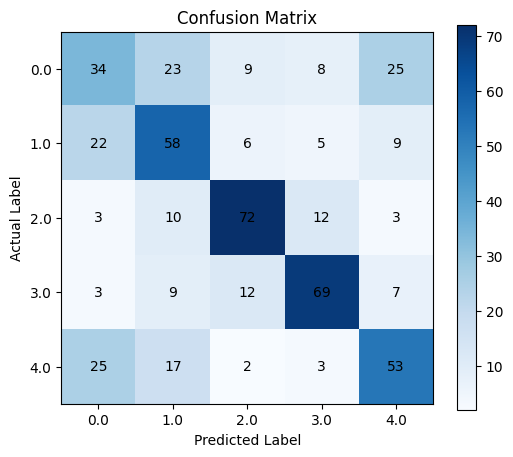

Accuracy: 0.5731462925851704
Plotting requires exactly 2 features.


In [ ]:
model = LDAClassifier()
model.fit(X_train, y_train)
print("\nValidation Results")
model.validate(X_dev, y_dev)

print("\nTesting Results")
y_pred = model.predict(X_test)

model.confusion_matrix(y_test, y_pred)
model.plot(X_test, y_test, "LDA Decision Boundary")


Validation Results
Validation Accuracy: 0.5350701402805611
Confusion Matrix:
 [[36 36  3  3 21]
 [23 66  1  2  8]
 [19 24 48  7  2]
 [11 22  2 61  4]
 [21 21  1  1 56]]


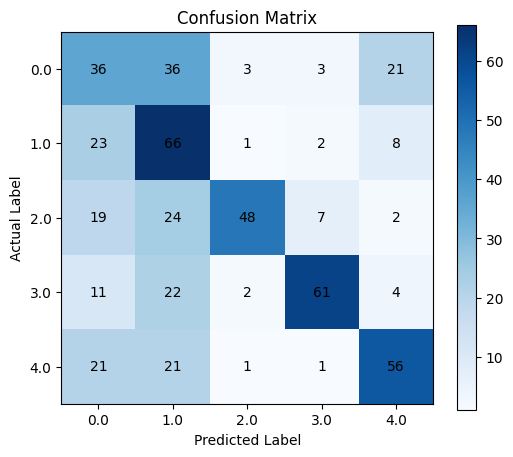

Accuracy: 0.5350701402805611

Testing Results
Confusion Matrix:
 [[35 40  6  3 15]
 [21 68  4  2  5]
 [11 27 51  4  7]
 [10 19  7 59  5]
 [36 26  1  1 36]]


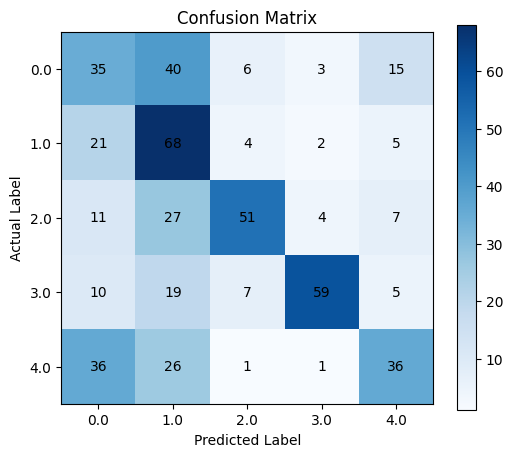

Accuracy: 0.49899799599198397
Plotting requires exactly 2 features.


In [ ]:
model = KNNClassifier()
model.fit(X_train, y_train)
print("\nValidation Results")
model.validate(X_dev, y_dev)

print("\nTesting Results")
y_pred = model.predict(X_test)

model.confusion_matrix(y_test, y_pred)
model.plot(X_test, y_test, "LDA Decision Boundary")


Validation Results
Validation Accuracy: 0.5490981963927856
Confusion Matrix:
 [[29 19 11 11 29]
 [18 39 17  9 17]
 [ 5 11 70 11  3]
 [ 2  4 21 66  7]
 [10 13  3  4 70]]


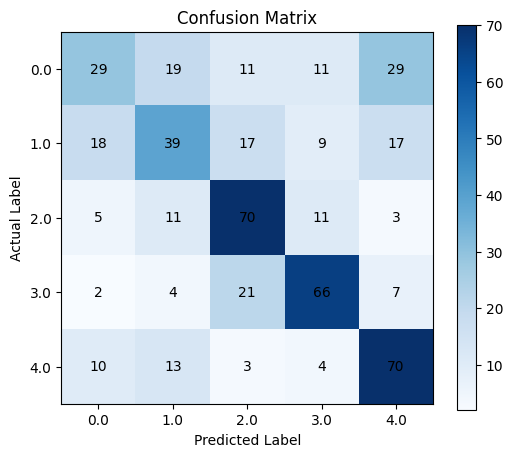

Accuracy: 0.5490981963927856

Testing Results
Confusion Matrix:
 [[18 20 16 10 35]
 [17 33 26  8 16]
 [ 6  6 71 12  5]
 [ 3  3 25 64  5]
 [15 11  5 12 57]]


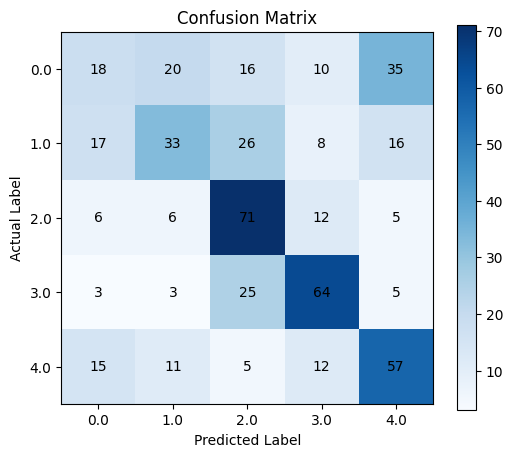

Accuracy: 0.48697394789579157
Plotting requires exactly 2 features.


In [ ]:
model = SVMClassifier()
model.fit(X_train, y_train)
print("\nValidation Results")
model.validate(X_dev, y_dev)

print("\nTesting Results")
y_pred = model.predict(X_test)

model.confusion_matrix(y_test, y_pred)
model.plot(X_test, y_test, "LDA Decision Boundary")